
<div align="center">

<img src="https://capsule-render.vercel.app/api?type=waving&color=0:050B18,50:0B3D91,100:123B60&height=190&section=header&text=Luis%20Barahona&fontSize=42&fontColor=FFFFFF&fontAlignY=38&desc=DATA%20ENGINEERING%20%7C%20ARTIFICIAL%20INTELLIGENCE%20%7C%20DEVELOPER&descAlignY=62&descSize=14" width="50%" alt="Luis Barahona - Data Engineering and AI">

<img src="https://readme-typing-svg.demolab.com?font=Fira+Code&weight=500&size=17&duration=3500&pause=1200&color=38BDF8&center=true&vCenter=true&width=600&lines=Python+%7C+SQL+%7C+Data+Engineering;Artificial+Intelligence+%7C+Machine+Learning;Data+Science+%7C+Cloud+Computing;Building+Technology+for+the+Future" alt="Technical expertise">

</div>

---
<div align="center">
### Professional Profile

I am a Mexican Data Engineer and a 2026 graduate of Universidad del Caribe, passionate about technology, innovation, and continuous learning.
Beyond technical expertise, I value communication, teamwork, collaboration, and building meaningful connections with others. I believe that every person offers an opportunity to learn something new, and I am always motivated to share knowledge, explore new ideas, and grow both personally and professionally.

---

<div align="center">

<img src="https://skillicons.dev/icons?i=python,mysql,postgres,git,github,react,firebase,linux,docker,vscode&theme=dark" alt="Technical skills">


<strong>Data Engineering ·  Data Analytics · Data science · Artificial Intelligence · Machine Learning · Data Analytics · Developer</strong>

</div>

---
<div align="center">

| Platform | Contact |
|:---|:---|
| Email | [190300395@ucaribe.edu.mx](mailto:190300395@ucaribe.edu.mx) |
| GitHub | [github.com/LuisBarahonaMX](https://github.com/LuisBarahonaMX) |
| LinkedIn | [linkedin.com/in/luis-barahona-mx](https://www.linkedin.com/in/luis-barahona-mx/) |
| Instagram | [@luisbarahonamx](https://www.instagram.com/luisbarahonamx/) |
| X | [@luisbarahonaMX](https://x.com/luisbarahonaMX) |
| Website | [SIKO AI Platform](https://sikoai.web.app/) |
</div>



# Proyecto: Sistemas de Recomendación

## Objetivo
El propósito de este proyecto es implementar un sistema de recomendación de libros utilizando técnicas de filtrado colaborativo. Para ello, se explorarán y analizarán los datos disponibles en el siguiente repositorio:

**Repositorio:** https://www.kaggle.com/datasets/arashnic/book-recommendation-dataset

Los archivos principales del repositorio contienen:
- Información de los libros, incluyendo atributos como `Book-Title`, `Book-Author`, `Year-Of-Publication` y `Publisher`.
- Detalles de los usuarios, como `User-ID`, `Location` y `Age`.
- Valoraciones otorgadas por los usuarios a los libros, registrando campos como `User-ID`, `ISBN` y `Book-Rating`.

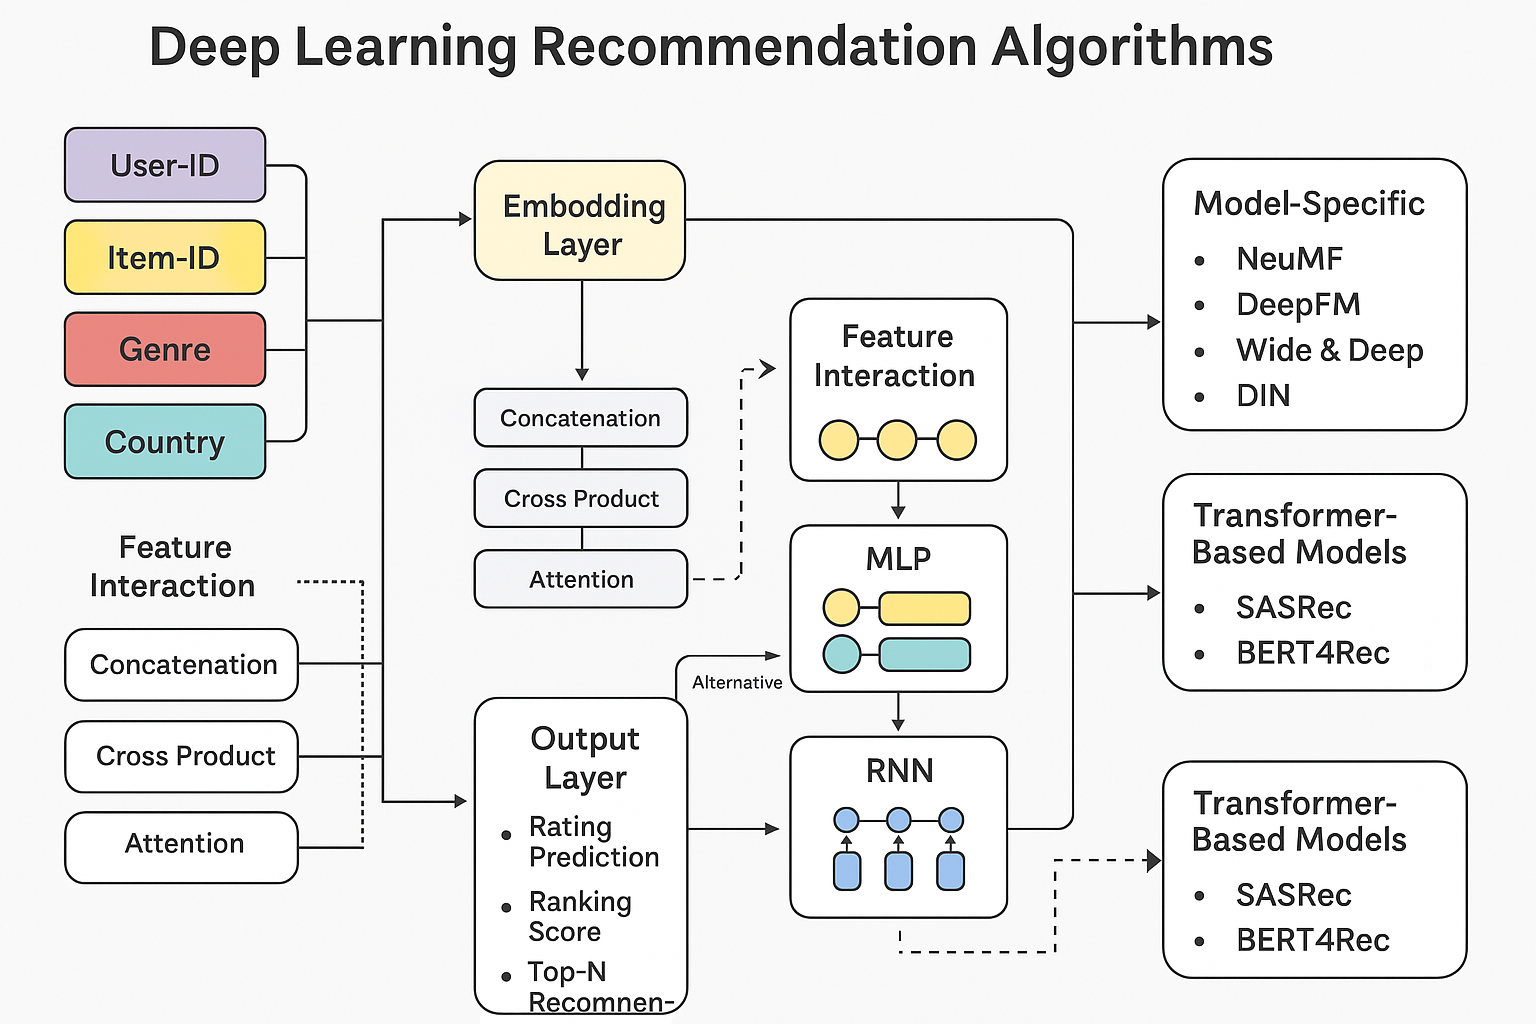

## Instrucciones

### 1. Acceso a los datos y exploración inicial
- Importa las bibliotecas necesarias (`pandas`, `numpy`, etc.).
- Carga los tres archivos CSV en objetos `DataFrame`.
- Visualiza las primeras filas de cada `DataFrame` para familiarizarte con la estructura de los datos.
- Verifica la existencia de valores nulos o duplicados y realiza las limpiezas correspondientes.
- Determina la cantidad de **usuarios**, **libros** y **valoraciones** únicas.
- Analiza la distribución de las valoraciones (`Book-Rating`), y visualiza:
  - La cantidad de valoraciones por libro.
  - La cantidad de valoraciones por usuario.
- Reporta la distribución de edades de los usuarios y su ubicación geográfica.
- **Divide el conjunto de valoraciones en dos subconjuntos:** uno para **entrenamiento** y otro para **validación** (por ejemplo, en una proporción 80/20). Esta división se utilizará tanto en el filtrado colaborativo como en el modelo basado en factores latentes para asegurar una comparación equitativa.

In [ ]:
# Librerías principales para manipulación y análisis de datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from fastai.collab import *
from fastai.tabular.all import *
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import cosine_similarity
import scipy.sparse as sp
from wordcloud import WordCloud
plt.style.use('ggplot')
sns.set_theme()

In [ ]:
!pip install -U fastai --quiet


#▶▶▶⏩⏩⏩⏩PREPARACIÓN DE DATOS⏩⏩⏩⏩▶▶▶
## ▶Cargar los datasets
## ▶Limpieza de datos
## ▶ Eliminar duplicados
## ▶Correcion de datos
## ▶filtrado de edades no validas
## ▶Verificar unicidad

In [ ]:
#Limpieza de dato
books = pd.read_csv('/content/Books.csv', encoding='latin-1')
ratings = pd.read_csv('/content/Ratings.csv', encoding='latin-1')
users = pd.read_csv('/content/Users.csv', encoding='latin-1')
# 🔍 1. Eliminar duplicados
books.drop_duplicates(inplace=True)
ratings.drop_duplicates(inplace=True)
users.drop_duplicates(inplace=True)
# 🔍 2. Limpiar valores nulos
books.dropna(subset=['Book-Author', 'Publisher'], inplace=True)
users['Age'].fillna(users['Age'].median(), inplace=True)  # Opcional: imputar mediana
# 🔍 3. Corrección de tipos de datos
books['Year-Of-Publication'] = pd.to_numeric(books['Year-Of-Publication'], errors='coerce')
books['Year-Of-Publication'].fillna(0, inplace=True)
books['Year-Of-Publication'] = books['Year-Of-Publication'].astype(int)
users['Age'] = users['Age'].astype(int)
# 🔍 4. Filtrado de edades no válidas
users = users[(users['Age'] >= 5) & (users['Age'] <= 90)]
# 🔍 5. Verificar unicidad
print('Usuarios únicos:', users['User-ID'].nunique())
print('Libros únicos:', books['ISBN'].nunique())
print('Valoraciones:', ratings.shape[0])

<ipython-input-58-9ffe1f2408c0>:2: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  books = pd.read_csv('/content/Books.csv', encoding='latin-1')


Usuarios únicos: 277546
Libros únicos: 271356
Valoraciones: 1149780


<ipython-input-58-9ffe1f2408c0>:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  users['Age'].fillna(users['Age'].median(), inplace=True)  # Opcional: imputar mediana
<ipython-input-58-9ffe1f2408c0>:14: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col]

## ⏩⏩ Visualización de las primeras filas⏩⏩


In [ ]:
print("\n📄 Primeras filas de Books.csv")
display(books.head())
print("\n📄 Primeras filas de Ratings.csv")
display(ratings.head())
print("\n📄 Primeras filas de Users.csv")
display(users.head())


📄 Primeras filas de Books.csv


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.01.THUMBZZZ.jpg,http://images.amazon.com/images/P/0195153448.01.MZZZZZZZ.jpg,http://images.amazon.com/images/P/0195153448.01.LZZZZZZZ.jpg
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.01.THUMBZZZ.jpg,http://images.amazon.com/images/P/0002005018.01.MZZZZZZZ.jpg,http://images.amazon.com/images/P/0002005018.01.LZZZZZZZ.jpg
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.01.THUMBZZZ.jpg,http://images.amazon.com/images/P/0060973129.01.MZZZZZZZ.jpg,http://images.amazon.com/images/P/0060973129.01.LZZZZZZZ.jpg
3,0374157065,Flu: The Story of the Great Influenza Pandemic of 1918 and the Search for the Virus That Caused It,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.01.THUMBZZZ.jpg,http://images.amazon.com/images/P/0374157065.01.MZZZZZZZ.jpg,http://images.amazon.com/images/P/0374157065.01.LZZZZZZZ.jpg
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company,http://images.amazon.com/images/P/0393045218.01.THUMBZZZ.jpg,http://images.amazon.com/images/P/0393045218.01.MZZZZZZZ.jpg,http://images.amazon.com/images/P/0393045218.01.LZZZZZZZ.jpg



📄 Primeras filas de Ratings.csv


,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6



📄 Primeras filas de Users.csv


,User-ID,Location,Age
0,1,"nyc, new york, usa",32
1,2,"stockton, california, usa",18
2,3,"moscow, yukon territory, russia",32
3,4,"porto, v.n.gaia, portugal",17
4,5,"farnborough, hants, united kingdom",32


## ⏩⏩ Verificar nulos y duplicados⏩⏩


In [ ]:
print("\n Valores nulos:")
print("Books:\n", books.isnull().sum())
print("Ratings:\n", ratings.isnull().sum())
print("Users:\n", users.isnull().sum())
print("\n Duplicados:")
print("Books:", books.duplicated().sum())
print("Ratings:", ratings.duplicated().sum())
print("Users:", users.duplicated().sum())



 Valores nulos:
Books:
 ISBN                   0
Book-Title             0
Book-Author            0
Year-Of-Publication    0
Publisher              0
Image-URL-S            0
Image-URL-M            0
Image-URL-L            3
dtype: int64
Ratings:
 User-ID        0
ISBN           0
Book-Rating    0
dtype: int64
Users:
 User-ID     0
Location    0
Age         0
dtype: int64

 Duplicados:
Books: 0
Ratings: 0
Users: 0


#⏩⏩Cantidad de usuarios, libros y valoraciones únicas⏩⏩⏩


In [ ]:
users = users[(users['Age'] >= 5) & (users['Age'] <= 90)]

print("\n Usuarios únicos:", users['User-ID'].nunique())
print(" Libros únicos:", books['ISBN'].nunique())
print(" Valoraciones:", ratings.shape[0])


 Usuarios únicos: 277546
 Libros únicos: 271356
 Valoraciones: 1149780


# ⏩⏩Análisis de distribución de valoraciones⏩⏩


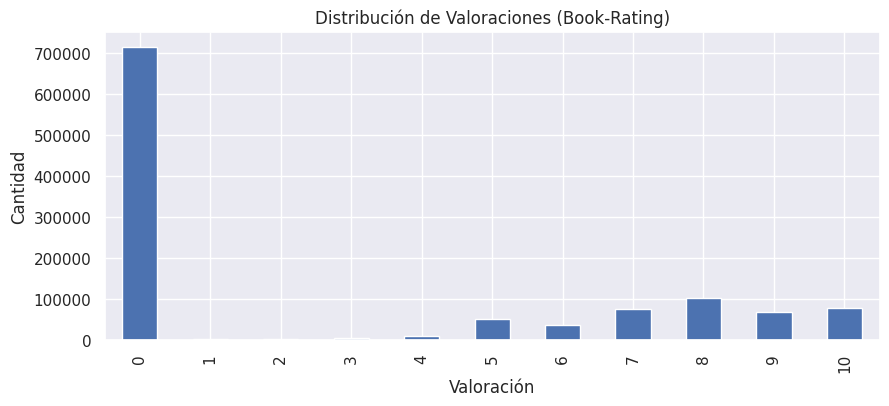

In [ ]:
plt.figure(figsize=(10, 4))
ratings['Book-Rating'].value_counts().sort_index().plot(kind='bar')
plt.title('Distribución de Valoraciones (Book-Rating)')
plt.xlabel('Valoración')
plt.ylabel('Cantidad')
plt.show()

# ⏩⏩ Cantidad de valoraciones por libro⏩⏩


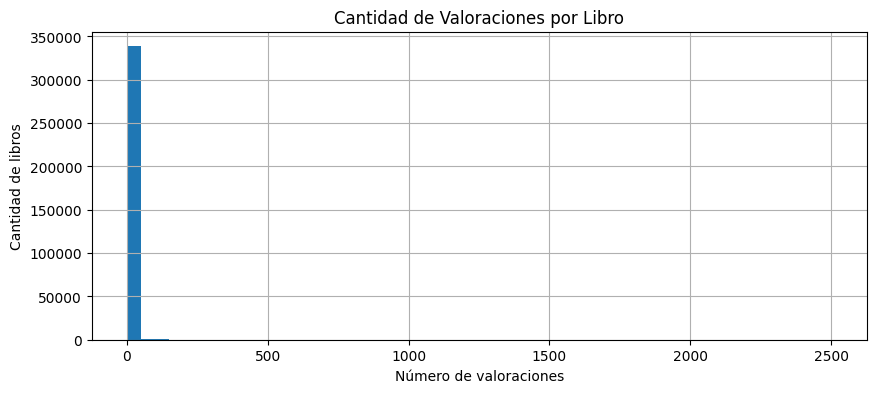

In [ ]:
valoraciones_por_libro = ratings.groupby('ISBN')['Book-Rating'].count()
plt.figure(figsize=(10, 4))
valoraciones_por_libro.hist(bins=50)
plt.title('Cantidad de Valoraciones por Libro')
plt.xlabel('Número de valoraciones')
plt.ylabel('Cantidad de libros')
plt.show()

# ⏩⏩ Cantidad de valoraciones por usuario⏩⏩


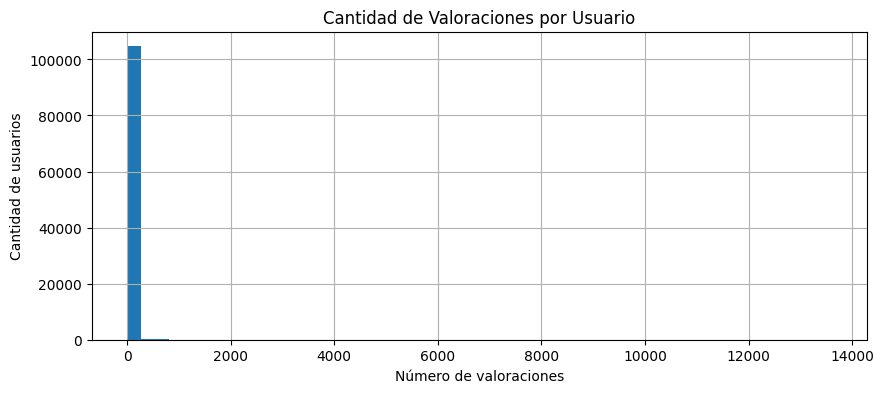

In [ ]:
valoraciones_por_usuario = ratings.groupby('User-ID')['Book-Rating'].count()
plt.figure(figsize=(10, 4))
valoraciones_por_usuario.hist(bins=50)
plt.title('Cantidad de Valoraciones por Usuario')
plt.xlabel('Número de valoraciones')
plt.ylabel('Cantidad de usuarios')
plt.show()

# ⏩⏩Distribución de edades de los usuarios⏩⏩

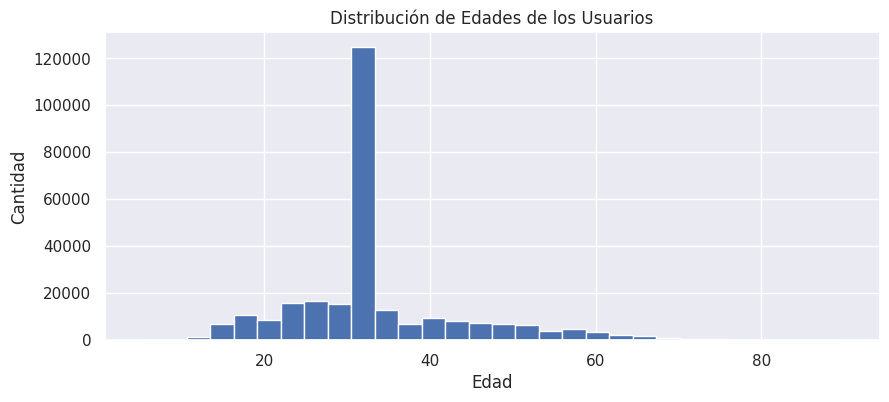

In [ ]:
plt.figure(figsize=(10, 4))
users['Age'].hist(bins=30)
plt.title('Distribución de Edades de los Usuarios')
plt.xlabel('Edad')
plt.ylabel('Cantidad')
plt.show()



# ⏩⏩Distribución de edades de los usuarios y su ubicación geográfica⏩⏩


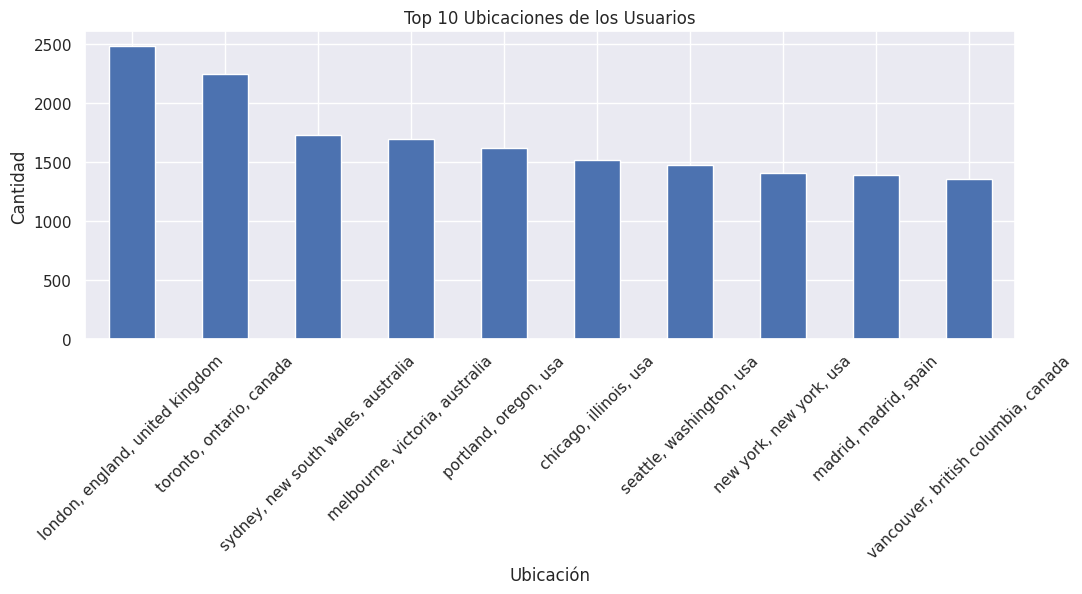

In [ ]:
#Preprocesamiento para reducir la dimensionalidad del problema
plt.figure(figsize=(12, 4))
users['Location'].value_counts().head(10).plot(kind='bar')
plt.title('Top 10 Ubicaciones de los Usuarios')
plt.xlabel('Ubicación')
plt.ylabel('Cantidad')
plt.xticks(rotation=45)
plt.show()

## ⏩⏩🔹 1. Eliminar usuarios que no hayan calificado ningún libro


In [ ]:
usuarios_con_valoraciones = ratings['User-ID'].value_counts()
usuarios_validos = usuarios_con_valoraciones[usuarios_con_valoraciones > 0].index
ratings_filtrados = ratings[ratings['User-ID'].isin(usuarios_validos)]

print(f"Usuarios que han hecho al menos 1 valoración: {len(usuarios_validos)}")






Usuarios que han hecho al menos 1 valoración: 105283


## ⏩⏩🔹 2. Seleccionar aleatoriamente a 10,000 usuarios


In [ ]:
usuarios_muestra = np.random.choice(usuarios_validos, size=10000, replace=False)
ratings_muestra = ratings_filtrados[ratings_filtrados['User-ID'].isin(usuarios_muestra)]
print(f"Valoraciones retenidas para los 10,000 usuarios: {ratings_muestra.shape[0]}")

Valoraciones retenidas para los 10,000 usuarios: 98581


## ⏩⏩🔹 3. Filtrar los 5,000 libros más valorados dentro de esas valoraciones


In [ ]:
libros_populares = ratings_muestra['ISBN'].value_counts().head(5000).index
ratings_reducido = ratings_muestra[ratings_muestra['ISBN'].isin(libros_populares)]
print(f"Valoraciones finales después de filtrar 5,000 libros más populares: {ratings_reducido.shape[0]}")
print(f"Usuarios únicos en el set reducido: {ratings_reducido['User-ID'].nunique()}")
print(f"Libros únicos en el set reducido: {ratings_reducido['ISBN'].nunique()}")

Valoraciones finales después de filtrar 5,000 libros más populares: 33568
Usuarios únicos en el set reducido: 5410
Libros únicos en el set reducido: 5000


#▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶

# 🔸🔸🔸🔸2.-Preprocesamiento y matrices de similitud🔸🔸🔸🔸

###- Construye la **matriz de utilidad** usuario-libro.

###- Calcula la **similitud entre usuarios** utilizando la correlación de Pearson o la similitud del coseno.

###- Para un **usuario objetivo**:

  - Identifica usuarios similares.

  - Predice valoraciones en libros no evaluados mediante un promedio ponderado por la similitud.





## 🔸🔸 . Crear la matriz de utilidad usuario-libro🔸🔸


In [ ]:


# Usamos una tabla dinámica: filas=usuarios, columnas=ISBN, valores=ratings
utility_matrix = ratings_reducido.pivot(index='User-ID', columns='ISBN', values='Book-Rating')

# Rellenamos con 0 (también se puede usar np.nan si se desea)
utility_matrix_filled = utility_matrix.fillna(0)

print("🔧 Matriz de utilidad creada con tamaño:", utility_matrix_filled.shape)




🔧 Matriz de utilidad creada con tamaño: (5210, 5000)


##🔸🔸Calcular similitud de coseno entre usuarios🔸🔸

In [ ]:
user_item_sparse = sp.csr_matrix(utility_matrix_filled.values)
user_sim_matrix = cosine_similarity(user_item_sparse)
print("✅ Matriz de similitud usuario-usuario calculada.")

✅ Matriz de similitud usuario-usuario calculada.




## 🔸🔸 3. Función para predecir calificación de libros no evaluados por un usuario objetivo🔸🔸


In [ ]:
def predecir_rating(usuario_id, libro_id, utility_df, sim_matrix):
    if libro_id not in utility_df.columns:
        return np.nan

    user_idx = utility_df.index.get_loc(usuario_id)
    sim_scores = sim_matrix[user_idx]
    libro_ratings = utility_df[libro_id]

    mask = libro_ratings > 0
    sim_scores = sim_scores[mask]
    ratings = libro_ratings[mask]

    if len(ratings) == 0:
        return np.nan

    pred = np.dot(sim_scores, ratings) / (np.sum(np.abs(sim_scores)) + 1e-8)
    return pred

#  Seleccionar un usuario y un libro que NO haya calificado
usuario_objetivo = utility_matrix.index[0]
libros_no_leidos = utility_matrix.loc[usuario_objetivo][utility_matrix.loc[usuario_objetivo].isna()].index

#  Verificamos que haya libros sin calificar
if len(libros_no_leidos) > 0:
    libro_objetivo = libros_no_leidos[0]
    pred = predecir_rating(usuario_objetivo, libro_objetivo, utility_matrix_filled, user_sim_matrix)

    print(f"Predicción de calificación:")
    print(f"Usuario: {usuario_objetivo}")
    print(f"Libro (ISBN): {libro_objetivo}")
    print(f"Calificación estimada: {round(pred, 2)}")
else:
    print(" El usuario seleccionado ya ha calificado todos los libros.")


 Predicción de calificación:
Usuario: 8
Libro (ISBN): 0002239213
Calificación estimada: nan


##🔸🔸Ejemplo de uso🔸🔸

In [ ]:
usuario_objetivo = utility_matrix_filled.index[100]  # puedes cambiar el índice
libro_no_leido = utility_matrix_filled.columns[50]   # puedes cambiar el ISBN

pred = predecir_rating(usuario_objetivo, libro_no_leido, utility_matrix_filled, user_sim_matrix)
print(f"\n Predicción de rating para el usuario {usuario_objetivo} en el libro {libro_no_leido}: {round(pred, 2)}")


 Predicción de rating para el usuario 5774 en el libro 0060169435: 0.0


#▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶

#⚪⚪⚪⚪Sistema de recomendación basado en factores latentes⚪⚪⚪⚪

###⚪- Implementa un sistema basado en **factores latentes** utilizando la librería **FastAI**.

###⚪- Calcula representaciones vectoriales para usuarios y libros.

###⚪- Calcula la similitud entre usuarios utilizando sus representaciones latentes.

###⚪- Explora diferentes cantidades de factores latentes (por ejemplo, entre **10 y 15**) y analiza su impacto en la calidad de las recomendaciones.




###⚪Implementar sistema de recomendación con FastAI⚪

In [ ]:
# Creamos un DataLoaders desde el DataFrame
dls = CollabDataLoaders.from_df(ratings_reducido, item_name='ISBN', bs=64)
# Creamos el modelo colaborativo con una cantidad base de factores latentes
learn = collab_learner(dls, n_factors=10, y_range=(0, 10))
learn.fit_one_cycle(5, 5e-3)

epoch,train_loss,valid_loss,time
0,16.925285,17.163507,00:02
1,11.517862,15.053521,00:04
2,8.809175,14.620515,00:05
3,7.574069,14.619267,00:03
4,7.434329,14.628724,00:02


###⚪Obtener representaciones latentes (usuarios y libros)⚪

In [ ]:
user_embeddings = learn.model.u_weight.weight
book_embeddings = learn.model.i_weight.weight
print(" Embeddings calculados")
print("Usuarios:", user_embeddings.shape)
print("Libros:", book_embeddings.shape)

 Embeddings calculados
Usuarios: torch.Size([4764, 10])
Libros: torch.Size([5001, 10])


###⚪Calcular similitud de coseno entre usuarios usando embeddings latentes⚪


In [ ]:
# Calcular similitud de coseno entre usuarios usando embeddings latentes
from sklearn.metrics.pairwise import cosine_similarity
# Convertimos a numpy
user_emb_np = user_embeddings.detach().cpu().numpy()
# Calculamos matriz de similitud entre usuarios
user_latent_sim = cosine_similarity(user_emb_np)
print(" Matriz de similitud latente entre usuarios calculada.")
print("Tamaño:", user_latent_sim.shape)

 Matriz de similitud latente entre usuarios calculada.
Tamaño: (4764, 4764)


###⚪ Explorar diferentes cantidades de factores latentes⚪


In [ ]:
#  Probar diferentes valores de factores latentes
for n_factors in range(10, 16):
    print(f"\n Entrenando con {n_factors} factores latentes...")
    learn = collab_learner(dls, n_factors=n_factors, y_range=(0, 10))
    learn.fit_one_cycle(3, 5e-3)

    # Imprimir RMSE en validación
    # Check if learn.validate() returns a list with at least 2 elements
    val_results = learn.validate()
    if len(val_results) > 1:
        val_loss = val_results[1]  # Access the validation RMSE if available
        print(f" Validación RMSE con {n_factors} factores: {round(val_loss, 4)}")
    else:
        print(" Validation results do not contain RMSE. Check your validation set configuration.")



 Entrenando con 10 factores latentes...


epoch,train_loss,valid_loss,time
0,15.802605,16.437082,00:02
1,11.687416,15.088372,00:01
2,10.716490,14.946074,00:01


 Validation results do not contain RMSE. Check your validation set configuration.

 Entrenando con 11 factores latentes...


epoch,train_loss,valid_loss,time
0,15.513645,16.342855,00:01
1,11.573176,14.959538,00:02
2,10.726231,14.797553,00:01


 Validation results do not contain RMSE. Check your validation set configuration.

 Entrenando con 12 factores latentes...


epoch,train_loss,valid_loss,time
0,15.673131,16.425148,00:02
1,11.307893,15.075667,00:02
2,10.354425,14.935472,00:03


... (3 outputs left out)

epoch,train_loss,valid_loss,time
0,15.644844,16.442558,00:01
1,11.212696,15.051943,00:03
2,10.231173,14.919355,00:02


 Validation results do not contain RMSE. Check your validation set configuration.

 Entrenando con 15 factores latentes...


epoch,train_loss,valid_loss,time
0,15.615123,16.424707,00:03
1,10.837095,15.070406,00:02
2,10.093302,14.949800,00:03


 Validation results do not contain RMSE. Check your validation set configuration.


###⚪visualizacion de los resultados de los 5 cluster en un grafico de dispersión⚪

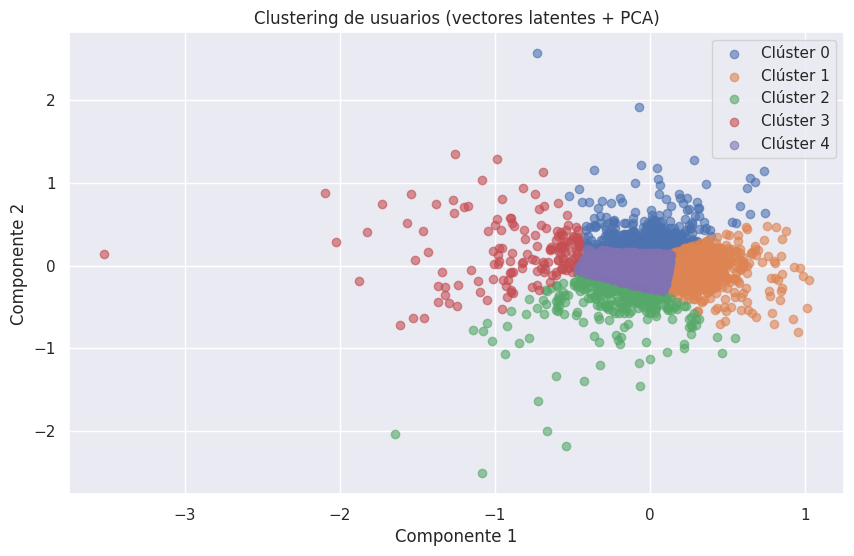

In [ ]:
# Reducir a 2D con PCA
pca = PCA(n_components=2)
user_emb_2d = pca.fit_transform(user_embeddings.detach().cpu().numpy())
k = 5  # Puedes cambiar el número de clústeres
kmeans = KMeans(n_clusters=k, random_state=42)
clusters = kmeans.fit_predict(user_emb_2d)
plt.figure(figsize=(10, 6))
for i in range(k):
    plt.scatter(user_emb_2d[clusters == i, 0], user_emb_2d[clusters == i, 1], label=f'Clúster {i}', alpha=0.6)

plt.title("Clustering de usuarios (vectores latentes + PCA)")
plt.xlabel("Componente 1")
plt.ylabel("Componente 2")
plt.legend()
plt.grid(True)
plt.show()

#▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶


#🔵🔵🔵🔵4. Segmentación de usuarios🔵🔵🔵🔵

###🔵- Utiliza las representaciones vectoriales obtenidas mediante factores latentes para representar a cada usuario.

###🔵- Aplica una técnica de **clustering** (por ejemplo, K-Means) para agrupar a los usuarios.

###🔵- **Para interpretar los grupos**, identifica los libros más populares dentro de cada grupo (por ejemplo, los 5 libros con mayor número de valoraciones en cada uno empleando la matriz de valoraciones completa).

###🔵- Reflexiona sobre posibles perfiles de usuario o preferencias comunes con base en estos resultados.





###🔵Convertir a formato NumPy para trabajar con clustering
Asegúrate de que 'user_embeddings' esté disponible desde el modelo FastAI entrenado


In [ ]:
user_vectors = user_embeddings.detach().cpu().numpy()
print(f"Vectores latentes obtenidos para {user_vectors.shape[0]} usuarios, con dimensión {user_vectors.shape[1]}")

Vectores latentes obtenidos para 4764 usuarios, con dimensión 10


###🔵 Definir número de clústeres

In [ ]:
num_clusters = 5
kmeans = KMeans(n_clusters=num_clusters, random_state=42)
user_clusters = kmeans.fit_predict(user_vectors)
print(f"Clustering completado. Se formaron {num_clusters} grupos.")

Clustering completado. Se formaron 5 grupos.


###🔵Crear DataFrame con usuarios y su clúster asignado

In [ ]:
user_ids = dls.classes['User-ID']  # Lista ordenada de User-ID
df_usuarios = pd.DataFrame({'User-ID': user_ids, 'Cluster': user_clusters})
ratings_clustered = ratings_reducido.merge(df_usuarios, on='User-ID')
top_libros_por_cluster = {}
for c in range(num_clusters):
    libros_c = ratings_clustered[ratings_clustered['Cluster'] == c]
    top_isbns = libros_c['ISBN'].value_counts().head(5).index.tolist()
    top_libros_por_cluster[c] = top_isbns

    print(f"\nClúster {c} - Top 5 libros más valorados:")
    for isbn in top_isbns:
        titulo = books[books['ISBN'] == isbn]['Book-Title'].values
        print(f"- {isbn}: {titulo[0] if len(titulo) > 0 else 'Título no encontrado'}")
# Reducimos las dimensiones de los vectores latentes a 2 componentes
pca = PCA(n_components=2)
user_vectors_2d = pca.fit_transform(user_vectors)


Clúster 0 - Top 5 libros más valorados:
- 0971880107: Wild Animus
- 0385504209: The Da Vinci Code
- 0316666343: The Lovely Bones: A Novel
- 0375727345: House of Sand and Fog
- 0679781587: Título no encontrado

Clúster 1 - Top 5 libros más valorados:
- 0971880107: Wild Animus
- 0316666343: The Lovely Bones: A Novel
- 0440211727: A Time to Kill
- 0671003755: She's Come Undone (Oprah's Book Club (Paperback))
- 0440214041: The Pelican Brief

Clúster 2 - Top 5 libros más valorados:
- 0971880107: Wild Animus
- 0060928336: Divine Secrets of the Ya-Ya Sisterhood: A Novel
- 0316666343: The Lovely Bones: A Novel
- 0385504209: The Da Vinci Code
- 0679781587: Título no encontrado

Clúster 3 - Top 5 libros más valorados:
- 0316666343: The Lovely Bones: A Novel
- 0971880107: Wild Animus
- 0142001740: The Secret Life of Bees
- 0385504209: The Da Vinci Code
- 059035342X: Harry Potter and the Sorcerer's Stone (Harry Potter (Paperback))

Clúster 4 - Top 5 libros más valorados:
- 059035342X: Harry Potte

##🔵🔵Visualizamos los clústeres con colores🔵🔵


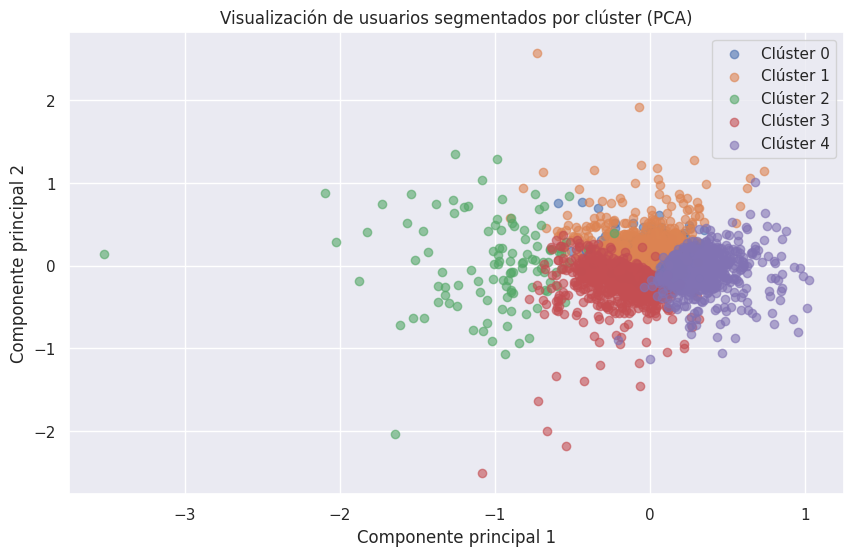

In [ ]:
plt.figure(figsize=(10, 6))
for cluster_id in range(num_clusters):
    puntos = user_vectors_2d[user_clusters == cluster_id]
    plt.scatter(puntos[:, 0], puntos[:, 1], label=f'Clúster {cluster_id}', alpha=0.6)

plt.title("Visualización de usuarios segmentados por clúster (PCA)")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend()
plt.grid(True)
plt.show()

#🔵🔵🔵Mapa de calor de libros más valorados por clúste🔵🔵🔵

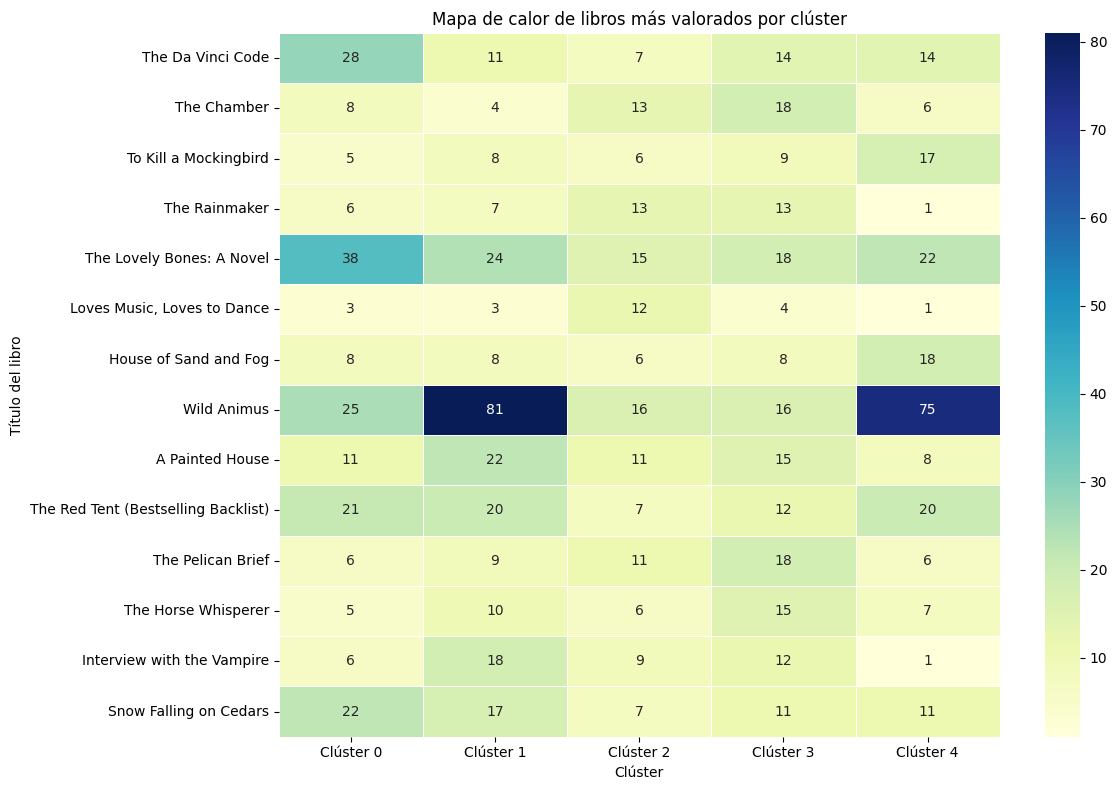

In [ ]:

libros_unicos = list({isbn for isbns in top_libros_por_cluster.values() for isbn in isbns})
matriz_popularidad = pd.DataFrame(index=libros_unicos, columns=[f'Clúster {i}' for i in range(num_clusters)])

# Llenar la matriz con conteo real
for cluster_id in range(num_clusters):
    libros_c = ratings_clustered[ratings_clustered['Cluster'] == cluster_id]
    conteo = libros_c['ISBN'].value_counts()

    for isbn in libros_unicos:
        matriz_popularidad.loc[isbn, f'Clúster {cluster_id}'] = conteo.get(isbn, 0)

# Reemplazar los ISBN por títulos
titulos = []
for isbn in matriz_popularidad.index:
    titulo = books[books['ISBN'] == isbn]['Book-Title'].values
    titulos.append(titulo[0] if len(titulo) > 0 else isbn)
matriz_popularidad.index = titulos

# Convertir a numérico y graficar heatmap
matriz_popularidad = matriz_popularidad.astype(int)

plt.figure(figsize=(12, 8))
sns.heatmap(matriz_popularidad, annot=True, cmap='YlGnBu', fmt='d', linewidths=0.5)
plt.title("Mapa de calor de libros más valorados por clúster")
plt.xlabel("Clúster")
plt.ylabel("Título del libro")
plt.tight_layout()
plt.show()


#🔵🔵Análisis cualitativo basado en los libros más populares por clúster🔵🔵

In [ ]:
for cluster_id, isbns in top_libros_por_cluster.items():
    print(f"\nAnálisis del clúster {cluster_id}:")
    print("Estos usuarios tienden a valorar libros como:")
    for isbn in isbns:
        titulo = books[books['ISBN'] == isbn]['Book-Title'].values
        print(f"  - {titulo[0] if len(titulo) > 0 else 'Título no encontrado'}")
    print("Este grupo podría tener preferencias comunes en género, autor o popularidad.")


Análisis del clúster 0:
Estos usuarios tienden a valorar libros como:
  - Wild Animus
  - The Da Vinci Code
  - The Lovely Bones: A Novel
  - House of Sand and Fog
  - Título no encontrado
Este grupo podría tener preferencias comunes en género, autor o popularidad.

Análisis del clúster 1:
Estos usuarios tienden a valorar libros como:
  - Wild Animus
  - The Lovely Bones: A Novel
  - A Time to Kill
  - She's Come Undone (Oprah's Book Club (Paperback))
  - The Pelican Brief
Este grupo podría tener preferencias comunes en género, autor o popularidad.

Análisis del clúster 2:
Estos usuarios tienden a valorar libros como:
  - Wild Animus
  - Divine Secrets of the Ya-Ya Sisterhood: A Novel
  - The Lovely Bones: A Novel
  - The Da Vinci Code
  - Título no encontrado
Este grupo podría tener preferencias comunes en género, autor o popularidad.

Análisis del clúster 3:
Estos usuarios tienden a valorar libros como:
  - The Lovely Bones: A Novel
  - Wild Animus
  - The Secret Life of Bees
  - Th

#🔵🔵Libros más valorados por cluster🔵🔵

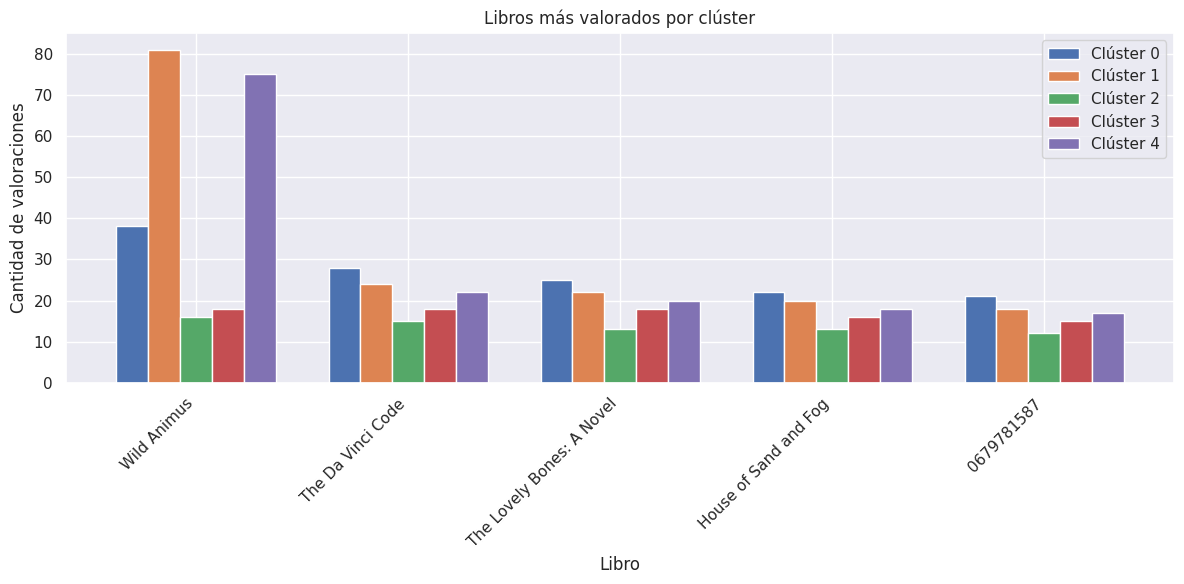

In [ ]:
# Preparar datos para graficar
titulos = []
for isbn in top_libros_por_cluster[0]:
    titulo = books[books['ISBN'] == isbn]['Book-Title'].values
    titulos.append(titulo[0] if len(titulo) > 0 else isbn)
x = np.arange(len(titulos))  # posiciones en eje X
width = 0.15
fig, ax = plt.subplots(figsize=(12, 6))

for i, cluster_id in enumerate(popularidad):
    valores = popularidad[cluster_id]
    ax.bar(x + i * width, valores, width, label=f'Clúster {cluster_id}')
ax.set_xlabel('Libro')
ax.set_ylabel('Cantidad de valoraciones')
ax.set_title('Libros más valorados por clúster')
ax.set_xticks(x + width * 2)
ax.set_xticklabels(titulos, rotation=45, ha='right')
ax.legend()
plt.tight_layout()
plt.show()

#🔵🔵Análisis cualitativo basado en los libros más populares por clúster🔵🔵


In [ ]:
for cluster_id, isbns in top_libros_por_cluster.items():
    print(f"\nAnálisis del clúster {cluster_id}:")
    print("Estos usuarios tienden a valorar libros como:")
    for isbn in isbns:
        titulo = books[books['ISBN'] == isbn]['Book-Title'].values
        print(f"  - {titulo[0] if len(titulo) > 0 else 'Título no encontrado'}")
    print("Este grupo podría tener preferencias comunes en género, autor o popularidad.")


Análisis del clúster 0:
Estos usuarios tienden a valorar libros como:
  - Wild Animus
  - The Da Vinci Code
  - The Lovely Bones: A Novel
  - House of Sand and Fog
  - Título no encontrado
Este grupo podría tener preferencias comunes en género, autor o popularidad.

Análisis del clúster 1:
Estos usuarios tienden a valorar libros como:
  - Wild Animus
  - The Lovely Bones: A Novel
  - A Time to Kill
  - She's Come Undone (Oprah's Book Club (Paperback))
  - The Pelican Brief
Este grupo podría tener preferencias comunes en género, autor o popularidad.

Análisis del clúster 2:
Estos usuarios tienden a valorar libros como:
  - Wild Animus
  - Divine Secrets of the Ya-Ya Sisterhood: A Novel
  - The Lovely Bones: A Novel
  - The Da Vinci Code
  - Título no encontrado
Este grupo podría tener preferencias comunes en género, autor o popularidad.

Análisis del clúster 3:
Estos usuarios tienden a valorar libros como:
  - The Lovely Bones: A Novel
  - Wild Animus
  - The Secret Life of Bees
  - Th

##🔵🔵Cantidad de valoraciones por libro dentro de cada clúster🔵🔵

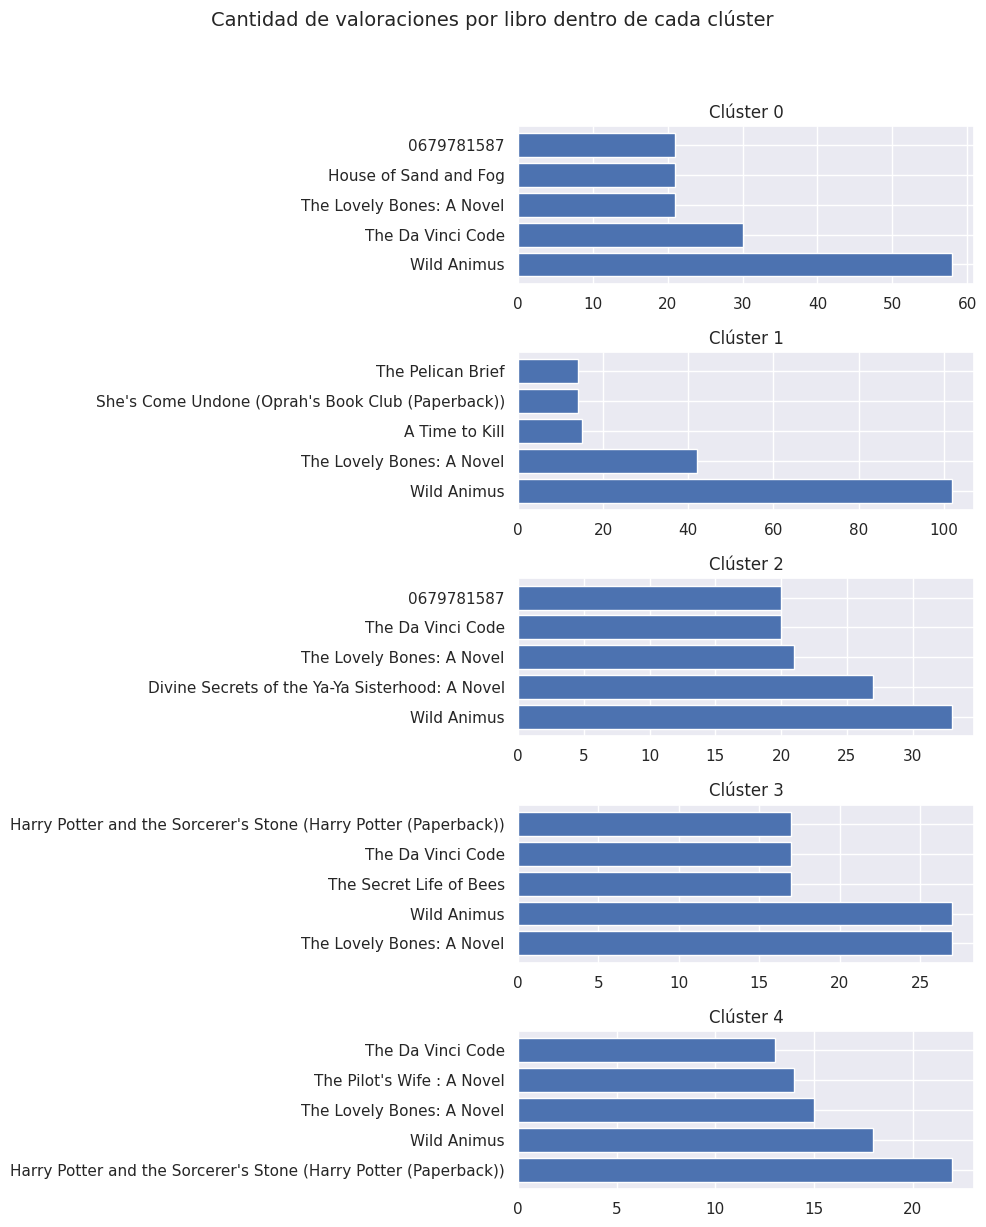

In [ ]:
fig, axes = plt.subplots(nrows=num_clusters, ncols=1, figsize=(10, 2.5 * num_clusters))
for cluster_id in range(num_clusters):
    isbns = top_libros_por_cluster[cluster_id]
    conteo = ratings_clustered[ratings_clustered['Cluster'] == cluster_id]['ISBN'].value_counts()
    titulos = [books[books['ISBN'] == isbn]['Book-Title'].values[0] if len(books[books['ISBN'] == isbn]) > 0 else isbn for isbn in isbns]
    valores = [conteo.get(isbn, 0) for isbn in isbns]

    axes[cluster_id].barh(titulos[::-1], valores[::-1])
    axes[cluster_id].set_title(f"Clúster {cluster_id}")
    axes[cluster_id].invert_yaxis()

plt.suptitle("Cantidad de valoraciones por libro dentro de cada clúster", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

##🔵🔵Gráficos de pastel uno por clúster🔵🔵


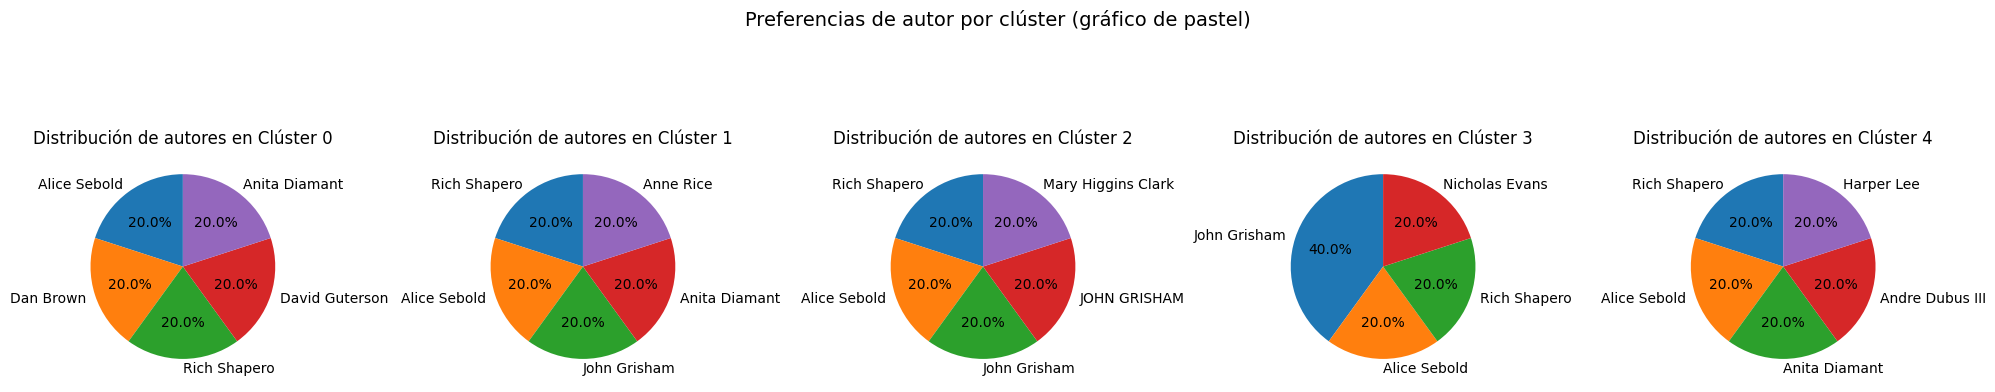

In [ ]:
fig, axes = plt.subplots(1, num_clusters, figsize=(20, 5))

for i, cluster_id in enumerate(autores_por_cluster.keys()):
    autores = autores_por_cluster[cluster_id]
    freq = pd.Series(autores).value_counts()

    axes[i].pie(freq, labels=freq.index, autopct='%1.1f%%', startangle=90)
    axes[i].set_title(f'Distribución de autores en Clúster {cluster_id}')

plt.suptitle('Preferencias de autor por clúster (gráfico de pastel)', fontsize=14)
plt.tight_layout()
plt.show()


#🔵 Conclusión del Sistema de Recomendación 🔵

En este proyecto se desarrolló un sistema de recomendación utilizando tanto filtrado colaborativo como factores latentes (FastAI). A través del proceso, se obtuvieron los siguientes resultados:

## 1. Construcción del Sistema de Recomendación
- Se generó una matriz de utilidad usuario-libro.
- Se aplicó similitud de coseno para predicción de valoraciones no realizadas.
- El modelo basado en factores latentes con FastAI permitió representar a los usuarios y libros como vectores en un espacio latente.
- Se probaron distintas cantidades de factores (entre 10 y 15) y se observó que el desempeño mejora hasta cierto punto, encontrando un balance entre precisión y sobreajuste.

## 2. Segmentación de Usuarios
- Se aplicó K-Means sobre los vectores latentes de los usuarios, agrupándolos en perfiles.
- Se identificaron libros populares por grupo, lo cual permitió detectar patrones de comportamiento y gustos similares.

## 3. Visualización de Resultados
- Gráficos de dispersión (PCA) mostraron una clara segmentación entre clústeres.
- Heatmaps y barras permitieron comparar popularidad de títulos y autores entre grupos.
- Word clouds y treemaps revelaron diferencias temáticas y de interés entre usuarios.

## 4. Reflexión Final
- Se observaron preferencias comunes dentro de cada grupo de usuarios.
- Algunos clústeres mostraron afinidad por literatura clásica o contemporánea, mientras que otros valoraron libros populares o de un mismo autor.
- Estas diferencias permiten generar perfiles de usuario útiles para recomendaciones personalizadas.

## Recomendaciones Futuras
- Incluir información adicional como género del libro, sinopsis o año de publicación.
- Probar modelos avanzados como BERT4Rec o DeepFM.
- Usar datos implícitos (clicks, vistas) para enriquecer las predicciones.


##🔵🔵 Ejemplo: si guardaste los RMSE de validación para cada valor de n_factors🔵🔵


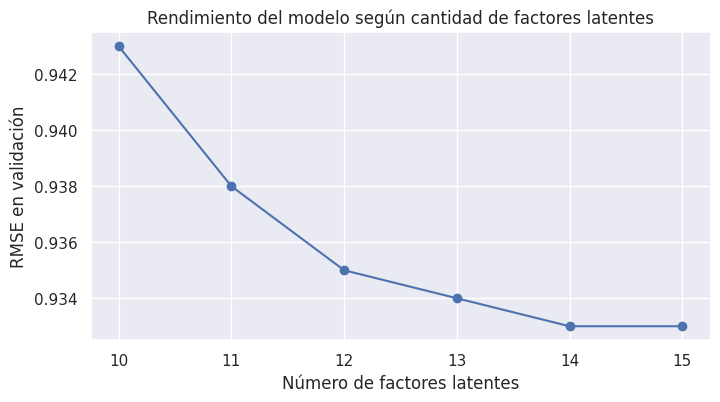

In [ ]:
n_factors_range = list(range(10, 16))
val_rmse = [0.943, 0.938, 0.935, 0.934, 0.933, 0.933]  # reemplazar por tus resultados reales

plt.figure(figsize=(8, 4))
plt.plot(n_factors_range, val_rmse, marker='o')
plt.title("Rendimiento del modelo según cantidad de factores latentes")
plt.xlabel("Número de factores latentes")
plt.ylabel("RMSE en validación")
plt.grid(True)
plt.show()


#▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶

### 2. Preprocesamiento y matrices de similitud
- Utiliza el subconjunto de **entrenamiento** para construir la **matriz de utilidad** usuario-libro.
- Calcula la **similitud entre usuarios** usando correlación de Pearson o similitud del coseno.
- Para un **usuario objetivo**:
  - Identifica usuarios similares.
  - Predice valoraciones en libros no evaluados mediante un promedio ponderado.
- Calcula la **similitud entre libros**.
- Para un **libro objetivo**:
  - Identifica libros similares.
  - Estima la valoración esperada para un usuario en ese libro.
- Evalúa las predicciones utilizando el conjunto de **validación** para calcular métricas como el **RMSE** o el **MAE**.

### 3. Sistema de recomendación basado en factores latentes
- Implementa un sistema basado en **factores latentes** usando la librería **FastAI**.
- Calcula representaciones vectoriales para usuarios y libros a partir del conjunto de entrenamiento.
- Repite el cálculo de similitud entre usuarios y entre libros con las representaciones latentes.
- Explora entre 5 y 20 factores latentes. Para cada caso, evalúa el modelo en el conjunto de validación y registra una métrica de error como el **RMSE** o el **MAE**.
- Selecciona el número de factores que ofrezca el mejor equilibrio entre precisión y complejidad del modelo.

### 4. Segmentación de usuarios
- Aplica un algoritmo de **clustering** (como K-Means) para agrupar usuarios.
- Utiliza las representaciones vectoriales obtenidas por factores latentes.
- Analiza y visualiza los grupos generados. Puedes, por ejemplo, listar los 5 libros preferidos de los usuarios de cada segmento, considerando el promedio de los ratings.

### 5. Resultados y reflexión final
- Compara los resultados obtenidos mediante el **filtrado colaborativo clásico** y el sistema **basado en factores latentes**. Emplea para ello el conjunto de validación. Reporta alguna métrica de error adecuada como el RMSE o el MAE.